# Credit Card Fraud Detection — Exploratory Data Analysis

## Project Overview

This project explores a credit card transaction dataset to understand transaction patterns and identify characteristics associated with fraudulent transactions.

## Objectives

- Understand the structure and characteristics of the dataset.
- Inspect missing values, duplicate records, and potential outliers.
- Explore numerical and categorical features.
- Analyze relationships between transaction features and the fraud target.
- Summarize the main findings and data preparation decisions.

## Dataset

The dataset contains transaction information, including transaction amounts, timestamps, merchant categories, customer-related attributes, geographic information, and a fraud indicator.

The target variable is `is_fraud`, where `0` represents a legitimate transaction and `1` represents a fraudulent transaction.



# 01. Data Understanding

This section examines the dataset structure, size, columns, statistical properties, unique values, and class distribution.

In [35]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check the current working directory
print("Current directory:")
print(os.getcwd())

# List files in the project folder
print("\nFiles and folders:")
print(os.listdir())

Current directory:
c:\Users\PRECISION\Desktop\ml proj

Files and folders:
['archive', 'Fraud_Detection_EDA.ipynb', 'venv']


In [36]:
# Load the training and testing datasets

train_path = os.path.join("archive", "fraudTrain.csv")
test_path = os.path.join("archive", "fraudTest.csv")

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)



In [5]:
df_train.sample(5, random_state=42)

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
1045211,1045211,2020-03-09 15:09:26,577588686219,fraud_Towne LLC,misc_pos,194.51,James,Strickland,M,25454 Leonard Lake,...,40.6153,-79.4545,972,Public relations account executive,1997-10-23,fff87d4340ef756a592eac652493cf6b,1362841766,40.420453,-78.865012,0
547406,547406,2019-08-22 15:49:01,30376238035123,fraud_Friesen Ltd,health_fitness,52.32,Cynthia,Davis,F,7177 Steven Forges,...,42.8250,-124.4409,217,Retail merchandiser,1928-10-01,d0ad335af432f35578eea01d639b3621,1345650541,42.758860,-123.636337,0
110142,110142,2019-03-04 01:34:16,4658490815480264,fraud_Mohr Inc,shopping_pos,6.53,Tara,Richards,F,4879 Cristina Station,...,39.9636,-79.7853,184,Systems developer,1945-11-04,87f26e3ea33f4ff4c7a8bad2c7f48686,1330824856,40.475159,-78.898190,0
1285953,1285953,2020-06-16 20:04:38,3514897282719543,fraud_Gaylord-Powlowski,home,7.33,Steven,Faulkner,M,841 Cheryl Centers Suite 115,...,42.9580,-77.3083,10717,Cytogeneticist,1952-10-13,9c34015321c0fa2ae6fd20f9359d1d3e,1371413078,43.767506,-76.542384,0
271705,271705,2019-05-14 05:54:48,6011381817520024,"fraud_Christiansen, Goyette and Schamberger",gas_transport,64.29,Kristen,Allen,F,8619 Lisa Manors Apt. 871,...,41.6423,-104.1974,635,Product/process development scientist,1973-07-13,198437c05676f485e9be04449c664475,1336974888,41.040392,-104.092324,0


In [38]:
print("Training dataset shape:", df_train.shape)
print("Testing dataset shape:", df_test.shape)

total_rows = df_train.shape[0] + df_test.shape[0]

print(f"\nTotal number of rows: {total_rows:,}")
print("Number of columns:", df_train.shape[1])

Training dataset shape: (1296675, 23)
Testing dataset shape: (555719, 23)

Total number of rows: 1,852,394
Number of columns: 23


In [7]:
df_train.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [39]:
df_train.nunique().sort_values(ascending=False)

Unnamed: 0               1296675
trans_num                1296675
merch_long               1275745
unix_time                1274823
trans_date_trans_time    1274791
merch_lat                1247805
amt                        52928
street                       983
cc_num                       983
zip                          970
long                         969
dob                          968
lat                          968
city                         894
city_pop                     879
merchant                     693
job                          494
last                         481
first                        352
state                         51
category                      14
gender                         2
is_fraud                       2
dtype: int64

In [8]:
df_train.isnull().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [9]:
# Check for duplicate rows
duplicates_count = df_train.duplicated().sum()

print("Number of duplicate rows:", duplicates_count)

Number of duplicate rows: 0


In [10]:
# Statistical summary of transaction amounts
df_train["amt"].describe()

count    1.296675e+06
mean     7.035104e+01
std      1.603160e+02
min      1.000000e+00
25%      9.650000e+00
50%      4.752000e+01
75%      8.314000e+01
max      2.894890e+04
Name: amt, dtype: float64

In [11]:
Q1 = df_train["amt"].quantile(0.25)
Q3 = df_train["amt"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_train[
    (df_train["amt"] < lower_bound) |
    (df_train["amt"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of outliers:", len(outliers))
print(
    "Percentage of outliers:",
    round(len(outliers) / len(df_train) * 100, 2),
    "%"
)

Q1: 9.65
Q3: 83.14
IQR: 73.49
Lower Bound: -100.58499999999998
Upper Bound: 193.375
Number of outliers: 67290
Percentage of outliers: 5.19 %


### Outlier Detection Using IQR

The IQR method was applied to the `amt` column to identify unusually large or small transaction amounts. The lower bound was approximately -100.585, and the upper bound was 193.375.

A total of 67,290 transactions (5.19% of the training dataset) were identified as outliers. No values were below the lower bound because all transaction amounts were positive.

These observations will be retained because unusually large transactions may contain useful information for fraud detection. Outliers are not necessarily fraudulent transactions, so removing them without further investigation could lead to information loss.



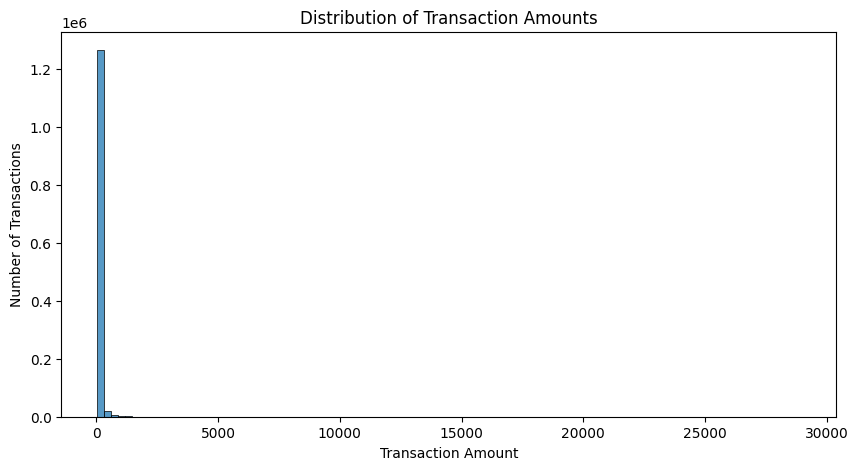

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_train,
    x="amt",
    bins=100
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.show()

### Transaction Amount Distribution

The histogram shows a strongly right-skewed distribution of transaction amounts. Most transactions have relatively small amounts, while a smaller number have much larger amounts. These extreme values stretch the horizontal axis and make the distribution of typical transaction amounts difficult to observe.

The identified outliers will be retained because large transaction amounts may be relevant to fraud detection.



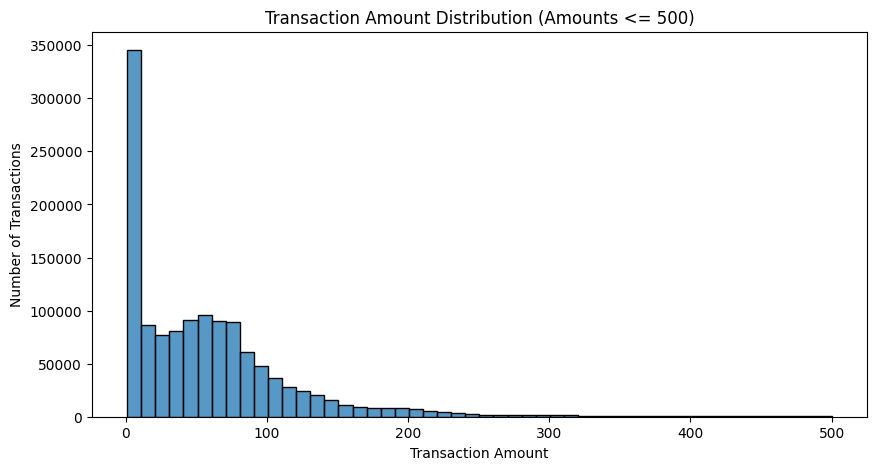

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_train[df_train["amt"] <= 500],
    x="amt",
    bins=50
)

plt.title("Transaction Amount Distribution (Amounts <= 500)")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.show()

### Detailed Transaction Amount Distribution

To better visualize the transaction amounts, a second histogram was created using transactions with amounts less than or equal to 500. This visualization shows that transaction amounts are concentrated at lower values and generally become less frequent as the amount increases.

The distribution remains right-skewed. The filtered data was used for visualization only; no transactions were removed from the original dataset.




In [14]:
# Count legitimate and fraudulent transactions
print(df_train["is_fraud"].value_counts())

# Calculate percentages
print("\nClass percentages:")
print(
    (df_train["is_fraud"].value_counts(normalize=True) * 100).round(2)
)

is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Class percentages:
is_fraud
0    99.42
1     0.58
Name: proportion, dtype: float64


In [17]:
# Convert transaction date to datetime
df_train["trans_date_trans_time"] = pd.to_datetime(
    df_train["trans_date_trans_time"]
)

df_test["trans_date_trans_time"] = pd.to_datetime(
    df_test["trans_date_trans_time"]
)

print(df_train["trans_date_trans_time"].dtype)
print(df_test["trans_date_trans_time"].dtype)

datetime64[ns]
datetime64[ns]


# 03. Exploratory Data Analysis (EDA)

This section explores individual features and investigates relationships between transaction characteristics and fraud status.

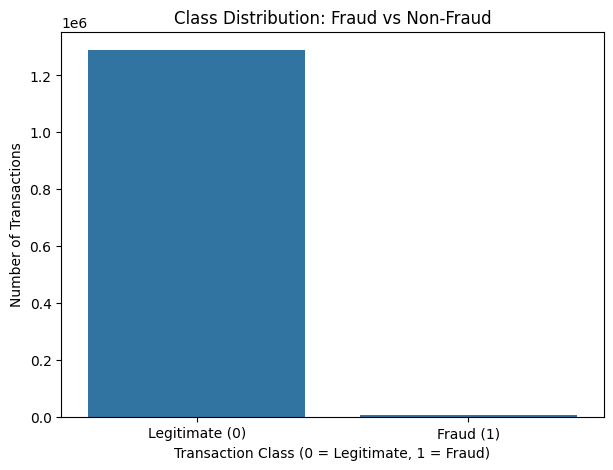

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_train, x="is_fraud")

plt.title("Class Distribution: Fraud vs Non-Fraud")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])

plt.show()

### Class Balance Analysis

The training dataset contains 1,296,675 transactions. Of these, 1,289,169 (99.42%) are legitimate, while 7,506 (0.58%) are fraudulent.

This indicates a severe class imbalance. Since fraudulent transactions represent a very small proportion of the dataset, accuracy alone would not be sufficient to evaluate a fraud detection model. Metrics such as precision, recall, and F1-score will also be important.



In [16]:
df_train.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

### Data Types and Memory Usage

The training dataset contains 1,296,675 rows and 23 columns. It includes 12 object columns, 6 integer columns, and 5 floating-point columns. The dataset uses approximately 1.1 GB of memory.

The transaction date (`trans_date_trans_time`) and date of birth (`dob`) are stored as object columns and may need conversion to datetime format for time-based analysis. No missing values were found during the previous missing-value check.



In [18]:
df_train.groupby("is_fraud")["amt"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
is_fraud,,,,,
0,1289169,67.667110,47.280,1.00,28948.90
1,7506,531.320092,396.505,1.06,1376.04


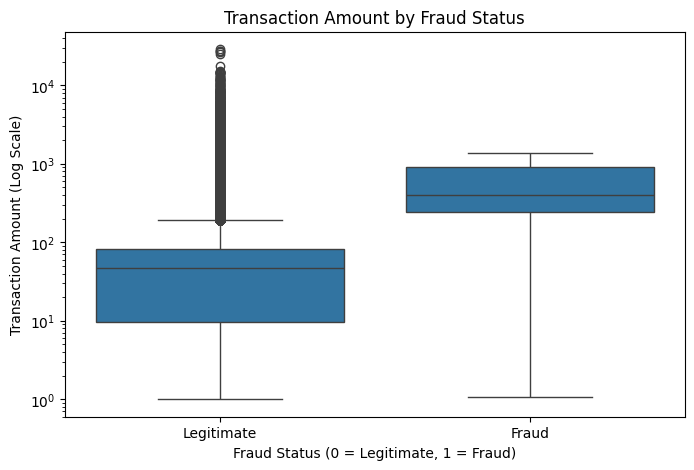

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_train,
    x="is_fraud",
    y="amt"
)

plt.yscale("log")
plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount (Log Scale)")
plt.xticks([0, 1], ["Legitimate", "Fraud"])

plt.show()

### Transaction Amount vs Fraud Status

The group-by analysis shows that fraudulent transactions have a higher average amount (531.32) and median amount (396.505) than legitimate transactions, whose average is 67.67 and median is 47.28.

This suggests that transaction amount may be a useful feature for fraud analysis. However, amount alone cannot determine whether a transaction is fraudulent, and some legitimate transactions have very large amounts. Further analysis of other features is needed.



In [20]:
fraud_by_category = df_train.groupby("category")["is_fraud"].agg(
    ["count", "sum", "mean"]
)

fraud_by_category.columns = [
    "total_transactions",
    "fraud_transactions",
    "fraud_rate"
]

fraud_by_category["fraud_rate"] *= 100

fraud_by_category.sort_values(
    "fraud_rate",
    ascending=False
).round(2)

,total_transactions,fraud_transactions,fraud_rate
category,,,
shopping_net,97543,1713,1.76
misc_net,63287,915,1.45
grocery_pos,123638,1743,1.41
shopping_pos,116672,843,0.72
gas_transport,131659,618,0.47
misc_pos,79655,250,0.31
grocery_net,45452,134,0.29
travel,40507,116,0.29
entertainment,94014,233,0.25


### Transaction Category vs Fraud

Fraud rates vary across transaction categories. The highest fraud rate in this training dataset was observed in `shopping_net` (1.76%), followed by `misc_net` (1.45%) and `grocery_pos` (1.41%). The lowest rate was observed in `health_fitness` (0.15%).

These results suggest that transaction category may be useful for exploring fraud patterns. However, the observed rates do not prove that a category causes fraud.



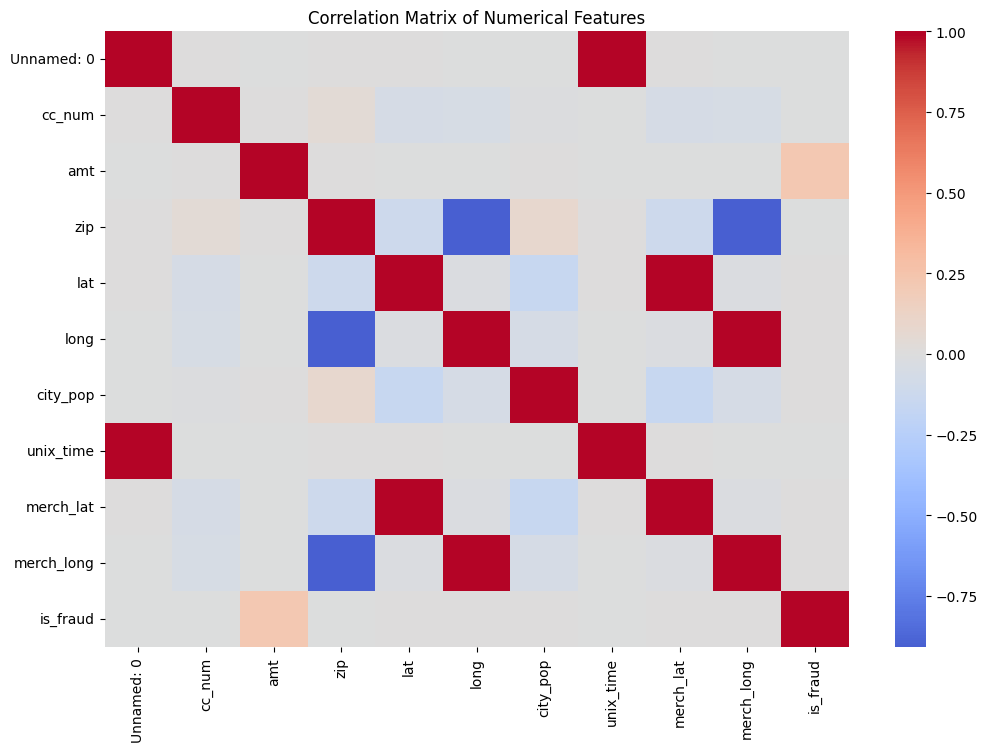

In [21]:
# Select numerical columns for correlation analysis
numeric_df = df_train.select_dtypes(include=["int64", "float64"])

# Plot correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

### Correlation Analysis

The correlation heatmap shows a positive relationship between transaction amount (`amt`) and the fraud target (`is_fraud`). A strong positive correlation is also observed between `Unnamed: 0` and `unix_time`, likely because these columns are related to record ordering and transaction time.

Some geographic variables also show correlations, including `lat` and `merch_lat`. Most other numerical feature pairs have weak linear correlations.

Correlation does not imply causation. The `Unnamed: 0` column should be reviewed because it appears to be an index-like column rather than a meaningful transaction feature.



In [22]:
# Count unique values in each column
df_train.nunique().sort_values(ascending=False)

Unnamed: 0               1296675
trans_num                1296675
merch_long               1275745
unix_time                1274823
trans_date_trans_time    1274791
merch_lat                1247805
amt                        52928
street                       983
cc_num                       983
zip                          970
long                         969
dob                          968
lat                          968
city                         894
city_pop                     879
merchant                     693
job                          494
last                         481
first                        352
state                         51
category                      14
gender                         2
is_fraud                       2
dtype: int64

### Unique Values and High Cardinality

The unique-value analysis shows that `Unnamed: 0` and `trans_num` have a unique value for every training record. The `merchant` column contains 693 distinct values, while `category` contains 14 transaction categories. The target column `is_fraud` contains two distinct classes.

Columns with many unique values, such as transaction identifiers and card numbers, should be reviewed carefully because they may act as identifiers rather than generalizable predictive features. Personal information should also be handled carefully.



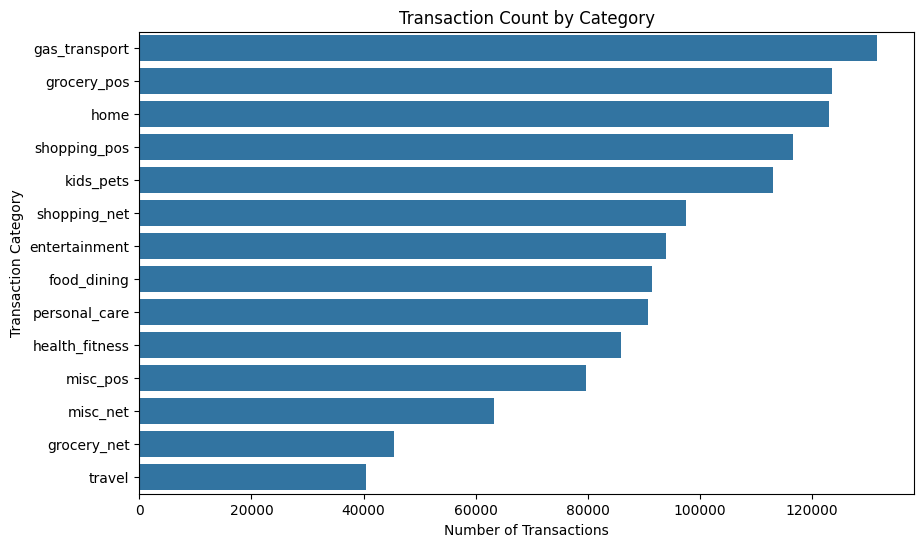

In [23]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_train,
    y="category",
    order=df_train["category"].value_counts().index
)

plt.title("Transaction Count by Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Transaction Category")
plt.show()

### Univariate Analysis: Transaction Category

The bar chart shows the distribution of transactions across 14 categories. `gas_transport` is the most frequent category, followed by `grocery_pos` and `home`. `travel` is the least frequent category.

This indicates that transaction frequencies vary across categories in the training dataset.



In [24]:
pd.crosstab(
    df_train["gender"],
    df_train["is_fraud"],
    normalize="index"
).mul(100).round(2)

is_fraud,0,1
gender,,
F,99.47,0.53
M,99.36,0.64


### Gender vs Fraud Status

The cross-tabulation shows that the fraud rate is 0.53% for female customers and 0.64% for male customers in the training dataset. The observed difference is small, and this comparison alone does not establish a meaningful relationship between gender and fraud.



## 04. Final Findings

### Key Findings

1. The training dataset contains 1,296,675 transactions and 23 columns.
2. No missing values or fully duplicated rows were found in the training dataset.
3. The `amt` feature contains 67,290 IQR-identified outliers (5.19%). These observations were retained because they may be relevant to fraud detection.
4. The dataset is highly imbalanced: 99.42% of transactions are legitimate and 0.58% are fraudulent.
5. Fraudulent transactions have higher average and median amounts than legitimate transactions in the training dataset.
6. Fraud rates vary across transaction categories, with `shopping_net` showing the highest rate in the category analysis.
7. The correlation analysis showed a positive relationship between transaction amount and the fraud target.

### Data Cleaning Decisions

- No missing-value imputation was required for the training dataset.
- No rows were removed for full-row duplication.
- IQR-identified outliers were retained to avoid losing potentially useful information.
- The transaction timestamp was converted to datetime format for time-based analysis.

### Conclusion

The exploratory data analysis identified class imbalance, differences in transaction amounts, and variation in fraud rates across categories. These findings can guide future feature preparation and model evaluation. Since fraud is rare, accuracy alone will not be sufficient to assess a future fraud detection model.

